In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../../datasets/heart.csv")

numerical_columns = df.select_dtypes(include="number").columns.tolist()

print("Numerical columns:", numerical_columns)
print("Dataset shape:", df.shape)

Numerical columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
Dataset shape: (1025, 14)


In [2]:
def manual_histogram(values, number_of_bins=10):
    values = [float(x) for x in values if pd.notna(x)]

    if len(values) == 0:
        return [], [], 0, 0

    minimum = min(values)
    maximum = max(values)

    if minimum == maximum:
        return [minimum], [len(values)], minimum, maximum

    bin_width = (maximum - minimum) / number_of_bins
    frequencies = [0] * number_of_bins

    for value in values:
        bin_index = int((value - minimum) / bin_width)

        if bin_index >= number_of_bins:
            bin_index = number_of_bins - 1

        frequencies[bin_index] += 1

    bin_centers = [
        minimum + (i + 0.5) * bin_width
        for i in range(number_of_bins)
    ]

    return bin_centers, frequencies, minimum, maximum

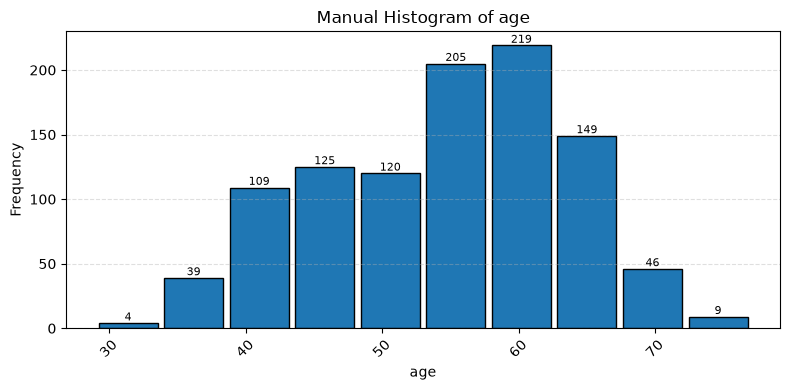

age: minimum=29.0, maximum=77.0, total frequency=1025


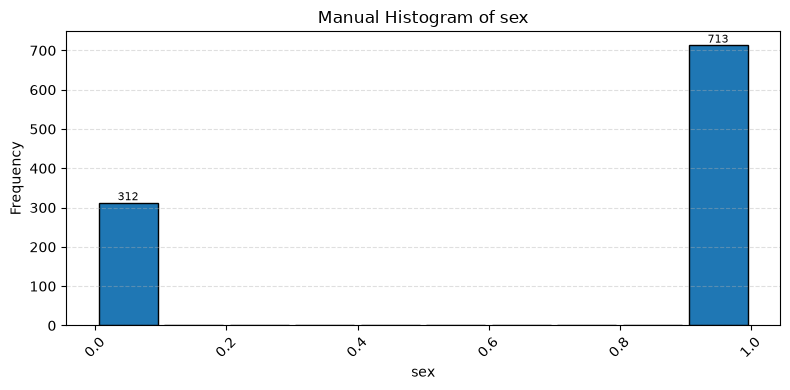

sex: minimum=0.0, maximum=1.0, total frequency=1025


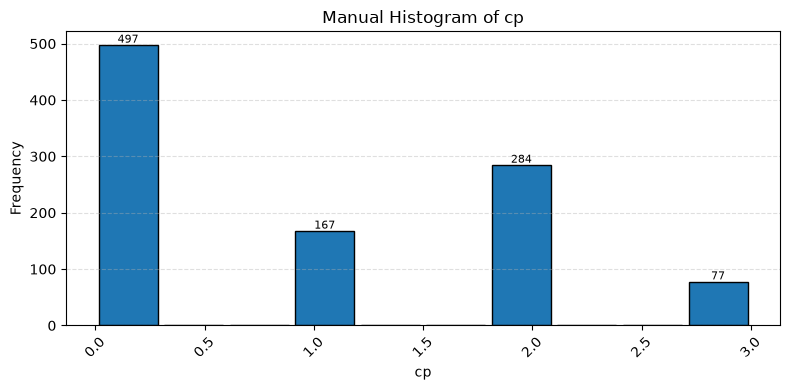

cp: minimum=0.0, maximum=3.0, total frequency=1025


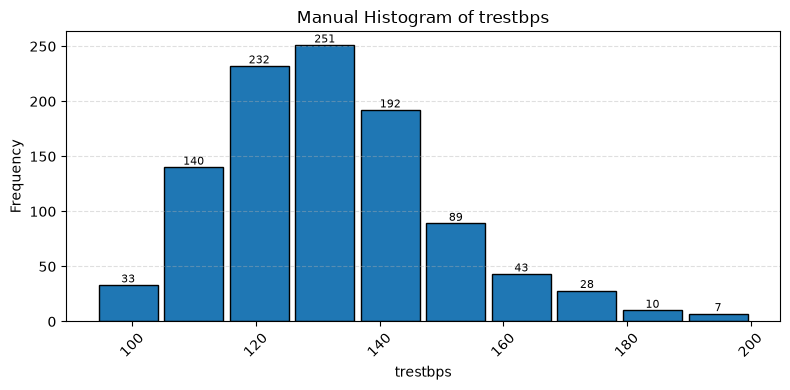

trestbps: minimum=94.0, maximum=200.0, total frequency=1025


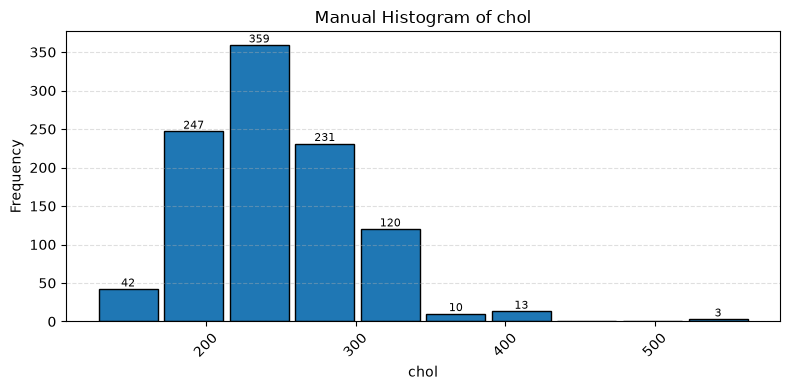

chol: minimum=126.0, maximum=564.0, total frequency=1025


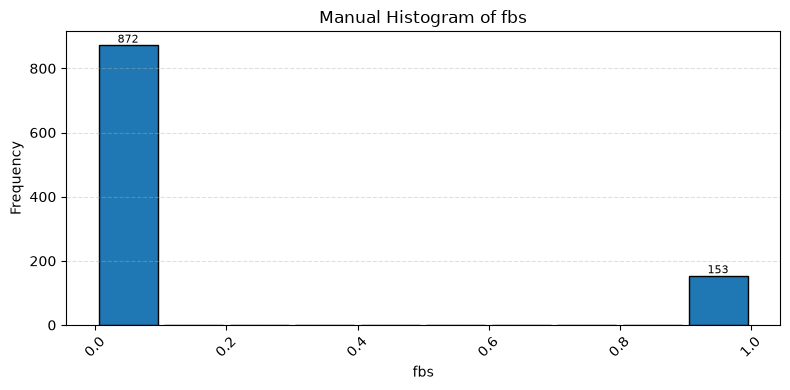

fbs: minimum=0.0, maximum=1.0, total frequency=1025


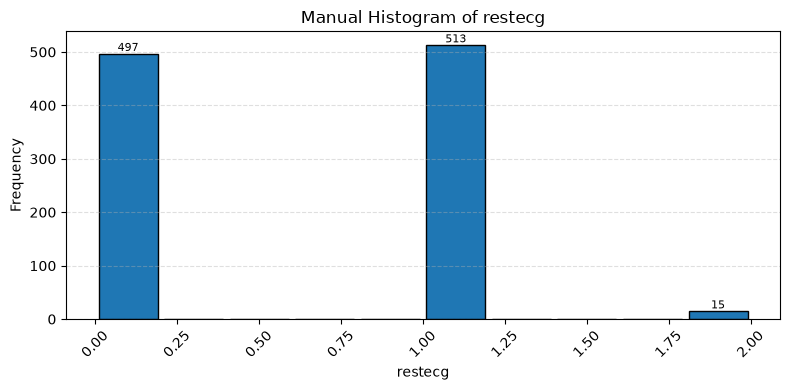

restecg: minimum=0.0, maximum=2.0, total frequency=1025


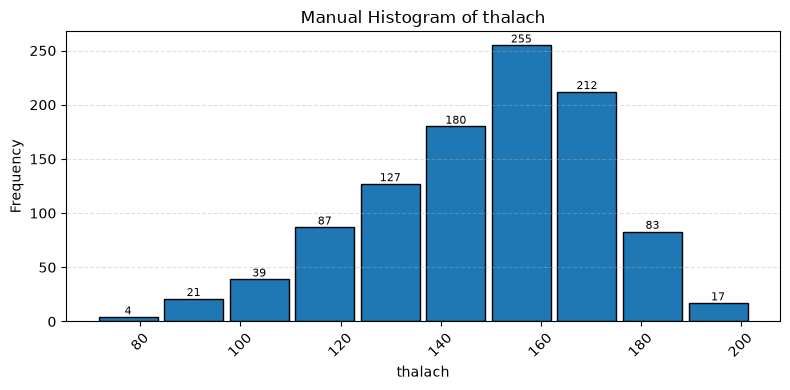

thalach: minimum=71.0, maximum=202.0, total frequency=1025


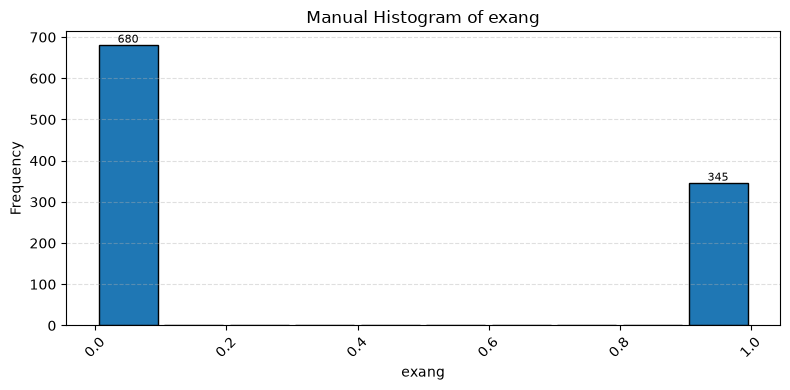

exang: minimum=0.0, maximum=1.0, total frequency=1025


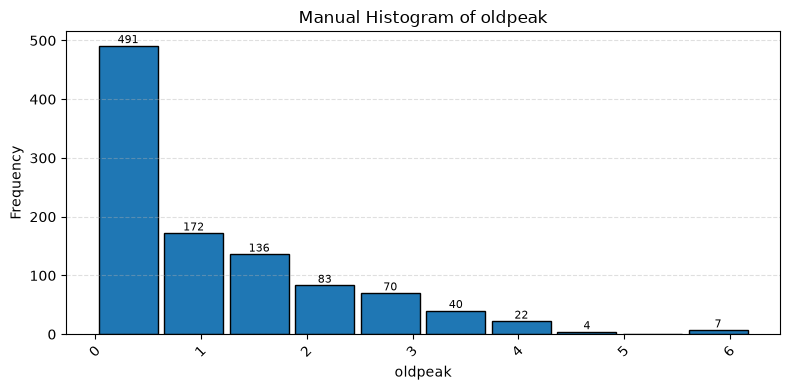

oldpeak: minimum=0.0, maximum=6.2, total frequency=1025


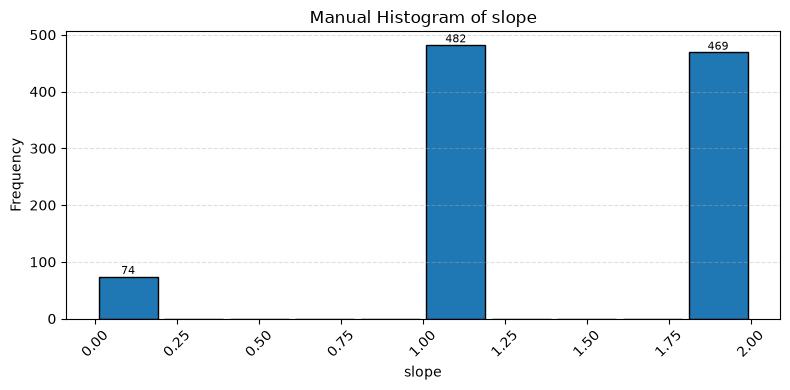

slope: minimum=0.0, maximum=2.0, total frequency=1025


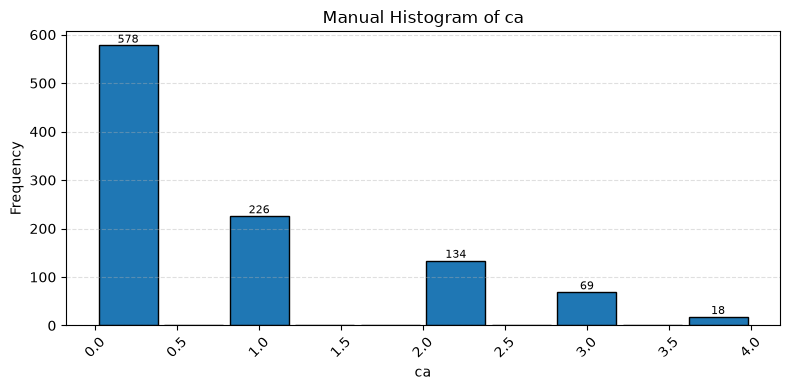

ca: minimum=0.0, maximum=4.0, total frequency=1025


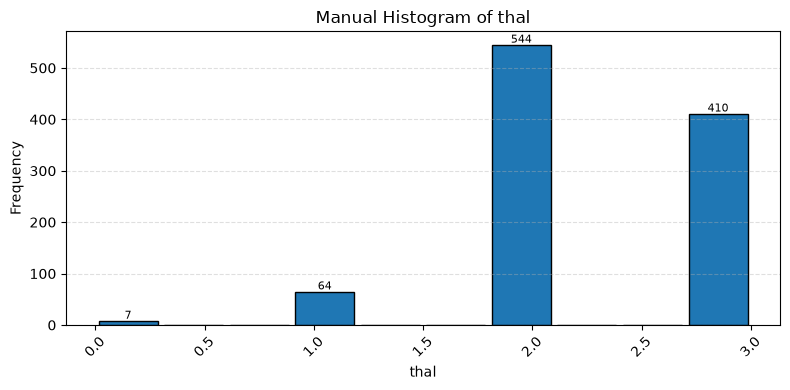

thal: minimum=0.0, maximum=3.0, total frequency=1025


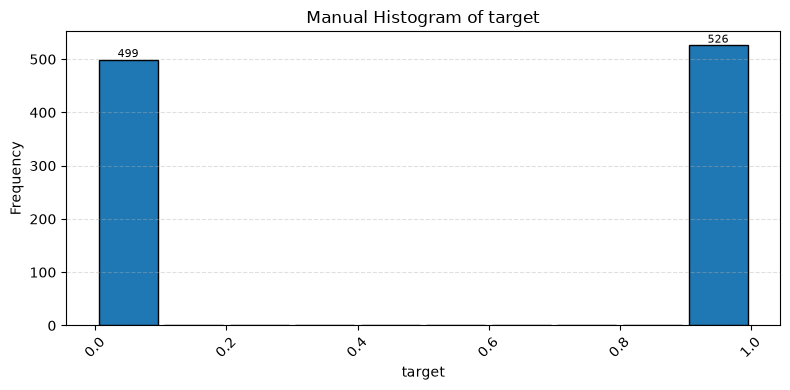

target: minimum=0.0, maximum=1.0, total frequency=1025


In [3]:
for col in numerical_columns:
    values = df[col].tolist()

    centers, frequencies, minimum, maximum = manual_histogram(
        values, number_of_bins=10
    )

    if len(centers) == 0:
        print(f"Skipping {col}: no valid numeric values.")
        continue

    if len(centers) == 1:
        bar_width = 0.8
    else:
        bar_width = centers[1] - centers[0]

    plt.figure(figsize=(8, 4))

    plt.bar(
        centers,
        frequencies,
        width=bar_width * 0.9,
        edgecolor="black",
        align="center"
    )

    plt.title(f"Manual Histogram of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.xticks(rotation=45)
    plt.grid(axis="y", linestyle="--", alpha=0.4)

    for x, frequency in zip(centers, frequencies):
        if frequency > 0:
            plt.text(
                x, frequency, str(frequency),
                ha="center", va="bottom", fontsize=8
            )

    plt.tight_layout()
    plt.show()

    print(
        f"{col}: minimum={minimum}, maximum={maximum}, "
        f"total frequency={sum(frequencies)}"
    )

In [4]:
for col in numerical_columns:
    values = [x for x in df[col].tolist() if pd.notna(x)]

    centers, frequencies, minimum, maximum = manual_histogram(
        values, number_of_bins=10
    )

    print(
        f"{col}: valid values={len(values)}, "
        f"sum of bin frequencies={sum(frequencies)}"
    )

    assert sum(frequencies) == len(values), (
        f"Frequency mismatch in {col}"
    )

print("\nAll histogram frequencies verified successfully.")

age: valid values=1025, sum of bin frequencies=1025
sex: valid values=1025, sum of bin frequencies=1025
cp: valid values=1025, sum of bin frequencies=1025
trestbps: valid values=1025, sum of bin frequencies=1025
chol: valid values=1025, sum of bin frequencies=1025
fbs: valid values=1025, sum of bin frequencies=1025
restecg: valid values=1025, sum of bin frequencies=1025
thalach: valid values=1025, sum of bin frequencies=1025
exang: valid values=1025, sum of bin frequencies=1025
oldpeak: valid values=1025, sum of bin frequencies=1025
slope: valid values=1025, sum of bin frequencies=1025
ca: valid values=1025, sum of bin frequencies=1025
thal: valid values=1025, sum of bin frequencies=1025
target: valid values=1025, sum of bin frequencies=1025

All histogram frequencies verified successfully.


# Task 11: Manual Histogram Creation

## Objective
To create histograms for numerical features without built-in histogram plotting functions by implementing binning and frequency calculations manually.

## Methodology
1. Loaded the Heart Disease dataset.
2. Identified numerical columns.
3. Calculated the minimum, maximum, and bin width for each feature.
4. Assigned observations to bins and counted frequencies using loops.
5. Visualized the calculated frequencies using Matplotlib bar plots.
6. Verified that the sum of bin frequencies matched the number of valid observations.

## Conclusion
Manual binning and frequency calculations were implemented for numerical features. The resulting histograms help examine distributions and identify concentrations of observations across value ranges.
